In [ ]:
from google.colab import files
import pandas as pd
uploaded=files.upload()
path=next(iter(uploaded))
preview=pd.read_excel(path)
print(preview.groupby(['model_version','simulation_status'],dropna=False).size())

Saving Final 160 Result Data.xlsx to Final 160 Result Data.xlsx
model_version  simulation_status
VAV_v1         成功                   160
dtype: int64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

def compare(path, version, final=False):
    df = pd.read_excel(path, sheet_name=0)
    features = ["wwr", "u_value", "shgc", "shading_depth_m"]
    df = df.dropna(subset=["design_id"]).copy()
    groups = df.groupby("glazing_id")
    if len(df) != 160 or df.design_id.duplicated().any() or len(groups) != 10 or not groups.size().eq(16).all():
        raise ValueError("Please keep all 160 unique design rows, including pending cases.")
    if df[features].isna().any().any() or df[features].duplicated().any():
        raise ValueError("Missing or duplicate facade inputs.")
    rng = np.random.default_rng(42)
    test_ids = set()
    for _, group in groups:
        test_ids.update(rng.choice(sorted(group.design_id), 3, replace=False))
    df["split"] = np.where(df.design_id.isin(test_ids), "test", "development")
    folder = Path("eui_final" if final else "eui_pilot")
    folder.mkdir(exist_ok=True)
    df[["design_id", "split"]].to_csv(folder/"split.csv", index=False)
    df["eui_simulated"] = pd.to_numeric(df.eui_simulated, errors="coerce")
    usable = df[df.simulation_status.astype(str).str.strip().eq("成功") &
                df.model_version.astype(str).str.strip().eq(version.strip()) &
                np.isfinite(df.eui_simulated) & df.eui_simulated.gt(0)].sort_values("design_id")
    train = usable[usable.split.eq("development")]
    test = usable[usable.split.eq("test")]
    print(f"Eligible {len(usable)}/160; development {len(train)}; reserved test {len(test)}")
    if len(train)<10 or (final and len(usable)!=160):
        raise ValueError("Check model_version, successful status and numeric EUI. Final mode requires 160 reviewed cases.")
    models = {"Linear": LinearRegression(), "Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)}
    folds = list(KFold(5, shuffle=True, random_state=42).split(train))
    results = []
    def evaluate(stage, data, predictions):
        rows = data[["design_id","glazing_id"] + features + ["eui_simulated"]].copy()
        y = rows.eui_simulated
        fig, axes = plt.subplots(1,2,figsize=(9,4),sharex=True,sharey=True)
        bounds = [min(np.min(v) for v in [y,*predictions.values()]),max(np.max(v) for v in [y,*predictions.values()])]
        for ax,(name,pred) in zip(axes,predictions.items()):
            error = pred-y
            rows[name+"_pred"] = pred
            rows[name+"_abs_error"] = abs(error)
            results.append(dict(stage=stage,model=name,n=len(y),MAE=mean_absolute_error(y,pred),RMSE=mean_squared_error(y,pred)**0.5,R2=r2_score(y,pred)))
            ax.scatter(y,pred,s=18); ax.plot(bounds,bounds,"k--",lw=1)
            ax.set(xlabel="EnergyPlus EUI",title=name,aspect="equal")
        axes[0].set_ylabel("Predicted EUI")
        fig.tight_layout(); fig.savefig(folder/(stage+".png"),dpi=200); plt.show(); plt.close(fig)
        rows.to_csv(folder/(stage+"_predictions.csv"), index=False, encoding="utf-8-sig")
    x, y = train[features], train.eui_simulated
    evaluate("development_cv",train,{k:cross_val_predict(m,x,y,cv=folds) for k,m in models.items()})
    print("Lowest development MAE:",min(results,key=lambda row:row["MAE"])["model"])
    if final:
        evaluate("heldout_test",test,{k:m.fit(x,y).predict(test[features]) for k,m in models.items()})
    summary=pd.DataFrame(results)
    summary.to_csv(folder/"metrics.csv",index=False)
    print(summary.to_string(index=False))
    return folder


Eligible 160/160; development 130; reserved test 30


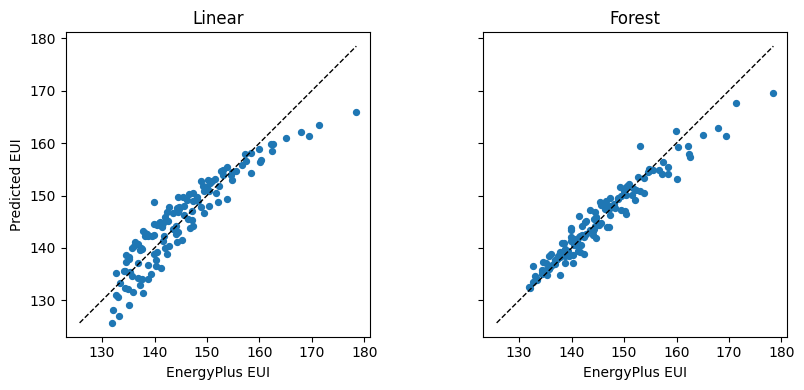

Lowest development MAE: Forest


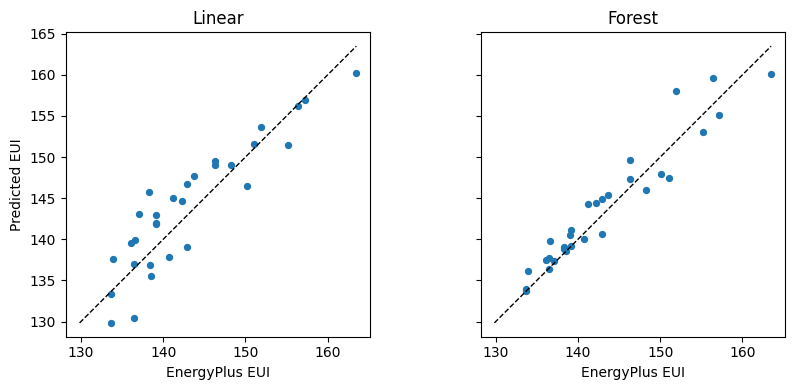

         stage  model   n      MAE     RMSE       R2
development_cv Linear 130 2.869305 3.458972 0.855507
development_cv Forest 130 1.781746 2.400633 0.930401
  heldout_test Linear  30 2.965672 3.424583 0.802208
  heldout_test Forest  30 1.830031 2.274459 0.912753


In [ ]:
VERSION = "VAV_v1"  # Replace with your reviewed Excel model_version
FINAL = True
folder = compare(path, VERSION, FINAL)

In [ ]:
import shutil
files.download(shutil.make_archive(str(folder),'zip',folder))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import json
import platform
import shutil

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from google.colab import files

# 1. 找到刚才导出的两份结果
results = Path("eui_final")
dev_name = "development_cv_predictions.csv"
test_name = "heldout_test_predictions.csv"

if not all((results / name).is_file() for name in [dev_name, test_name]):
    print("请同时上传 development_cv_predictions.csv 和 heldout_test_predictions.csv")
    uploaded = files.upload()
    results.mkdir(exist_ok=True)
    for name in [dev_name, test_name]:
        if name not in uploaded:
            raise ValueError(f"缺少文件：{name}")
        (results / name).write_bytes(uploaded[name])

dev = pd.read_csv(results / dev_name).sort_values("design_id")
test = pd.read_csv(results / test_name).sort_values("design_id")

# 2. 使用与原笔记本一致的四列输入和训练数据
features = ["wwr", "u_value", "shgc", "shading_depth_m"]
target = "eui_simulated"

assert len(dev) == dev["design_id"].nunique() == 130, "开发集应有 130 个不同方案"
assert len(test) == test["design_id"].nunique() == 30, "测试集应有 30 个不同方案"
assert set(dev["design_id"]).isdisjoint(test["design_id"]), "开发集和测试集编号有重叠"

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
model.fit(dev[features], dev[target])

# 3. 保存模型，再从磁盘加载，核对全部 30 个测试预测
out = Path("facade_rf_v1")
out.mkdir(exist_ok=True)
model_path = out / "random_forest.joblib"
joblib.dump(model, model_path)

saved_model = joblib.load(model_path)
predictions = saved_model.predict(test[features])
max_diff = np.max(np.abs(predictions - test["Forest_pred"].to_numpy()))

if not np.allclose(predictions, test["Forest_pred"], rtol=0, atol=1e-6):
    raise ValueError(
        f"与原测试预测的最大差异为 {max_diff:.6f}。"
        "请检查两份 CSV 是否来自同一次最终运行，以及 scikit-learn 版本是否一致。"
    )

# 4. 保存网站需要的输入说明和软件版本
metadata = {
    "model_version": "facade_rf_v1",
    "simulation_model_version": "VAV_v1",
    "features_in_order": features,
    "feature_units": ["fraction (0–1)", "W/(m²·K)", "fraction (0–1)", "m"],
    "target": target,
    "target_unit": "kWh/(m²·year)",
    "training_cases": len(dev),
    "heldout_cases": len(test),
    "heldout_mae": float(np.mean(np.abs(predictions - test[target]))),
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__
}
(out / "model_info.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
(out / "requirements.txt").write_text(
    f"scikit-learn=={sklearn.__version__}\n"
    f"numpy=={np.__version__}\n"
    f"pandas=={pd.__version__}\n"
    f"joblib=={joblib.__version__}\n",
    encoding="utf-8"
)

print(f"模型导出成功：已复现全部 {len(test)} 个独立测试预测。")
print(f"独立测试 MAE = {metadata['heldout_mae']:.3f} kWh/(m²·年)")
files.download(shutil.make_archive(str(out), "zip", out))

模型导出成功：已复现全部 30 个独立测试预测。
独立测试 MAE = 1.830 kWh/(m²·年)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>